In [ ]:
!pip install -q datasets scikit-learn

In [ ]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print(dataset)
print(dataset.column_names)
print(dataset[0]["class_label"])
print(dataset[0]["class_idx"])

README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})
['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']
Apple___Apple_scab
0


In [ ]:
train_data = dataset.filter(lambda x: x["split"] == "train")
test_data = dataset.filter(lambda x: x["split"] == "test")

train_indices, val_indices = train_test_split(
    np.arange(len(train_data)),
    test_size=0.15,
    random_state=42,
    stratify=train_data["class_idx"]
)

train_split = train_data.select(train_indices.tolist())
val_split = train_data.select(val_indices.tolist())

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))
print("Test samples:", len(test_data))

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Training samples: 36852
Validation samples: 6504
Test samples: 10948


In [ ]:
image_size = 224

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [ ]:
class PlantDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        item = self.data[index]

        image = item["image"].convert("RGB")
        label = int(item["class_idx"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
batch_size = 32

train_dataset = PlantDataset(train_split, train_transform)
val_dataset = PlantDataset(val_split, test_transform)
test_dataset = PlantDataset(test_data, test_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 36852
Validation samples: 6504
Test samples: 10948


In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Sample labels:", labels[:10])

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Sample labels: tensor([ 3, 25,  0, 16, 12, 13, 31, 16, 34, 19])


In [ ]:
class_mapping = {}

for idx, name in zip(
    dataset["class_idx"],
    dataset["class_label"]
):
    idx = int(idx)

    if idx in class_mapping and class_mapping[idx] != name:
        raise ValueError(f"Inconsistent class mapping for index {idx}")

    class_mapping[idx] = name

num_classes = len(class_mapping)
class_names = [class_mapping[i] for i in range(num_classes)]

print("Number of classes:", num_classes)

Number of classes: 38


In [ ]:
class PlantCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
model = PlantCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

PlantCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=256, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_fe

In [ ]:
def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


epochs = 10
best_val_loss = float("inf")
best_model = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    val_loss = evaluate_loss(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Train Loss: {train_loss:.4f} "
        f"- Val Loss: {val_loss:.4f}"
    )

model.load_state_dict(best_model)

print("Training completed.")
print("Best validation loss:", round(best_val_loss, 4))

Epoch 1/10 - Train Loss: 2.2442 - Val Loss: 1.4372
Epoch 2/10 - Train Loss: 1.2349 - Val Loss: 0.8101
Epoch 3/10 - Train Loss: 0.9355 - Val Loss: 0.6019
Epoch 4/10 - Train Loss: 0.7531 - Val Loss: 0.5119
Epoch 5/10 - Train Loss: 0.6453 - Val Loss: 0.4107
Epoch 6/10 - Train Loss: 0.5487 - Val Loss: 0.3422
Epoch 7/10 - Train Loss: 0.4747 - Val Loss: 0.2832
Epoch 8/10 - Train Loss: 0.4108 - Val Loss: 0.2662
Epoch 9/10 - Train Loss: 0.3685 - Val Loss: 0.1787
Epoch 10/10 - Train Loss: 0.3324 - Val Loss: 0.1779
Training completed.
Best validation loss: 0.1779


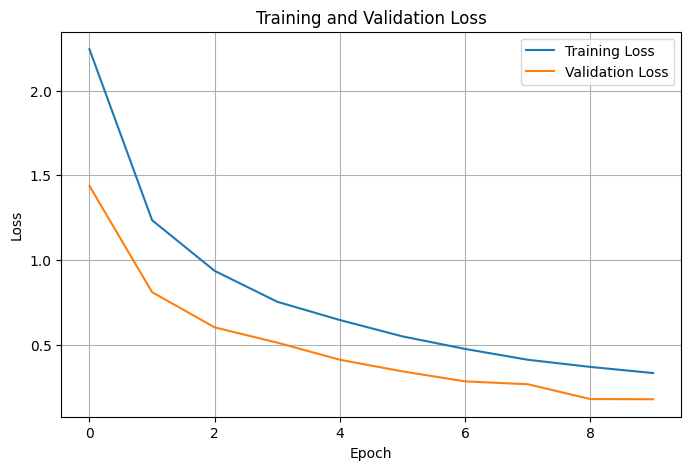

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print(f"Test Accuracy:  {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall:    {recall:.4f}")
print(f"Test F1-score:  {f1:.4f}")

Test Accuracy:  0.9357
Test Precision: 0.9207
Test Recall:    0.9152
Test F1-score:  0.9148


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.84      0.85      0.84       123
                                 Apple___Black_rot       0.94      0.90      0.92       124
                          Apple___Cedar_apple_rust       1.00      0.84      0.91        55
                                   Apple___healthy       0.87      0.91      0.89       324
                               Blueberry___healthy       0.89      0.99      0.93       278
          Cherry_(including_sour)___Powdery_mildew       0.96      0.95      0.95       252
                 Cherry_(including_sour)___healthy       0.88      0.99      0.93       179
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.81      0.84      0.83       103
                       Corn_(maize)___Common_rust_       0.99      0.98      0.99       238
               Corn_(maize)___Northern_Leaf_Blight       0.92      0.88      0.

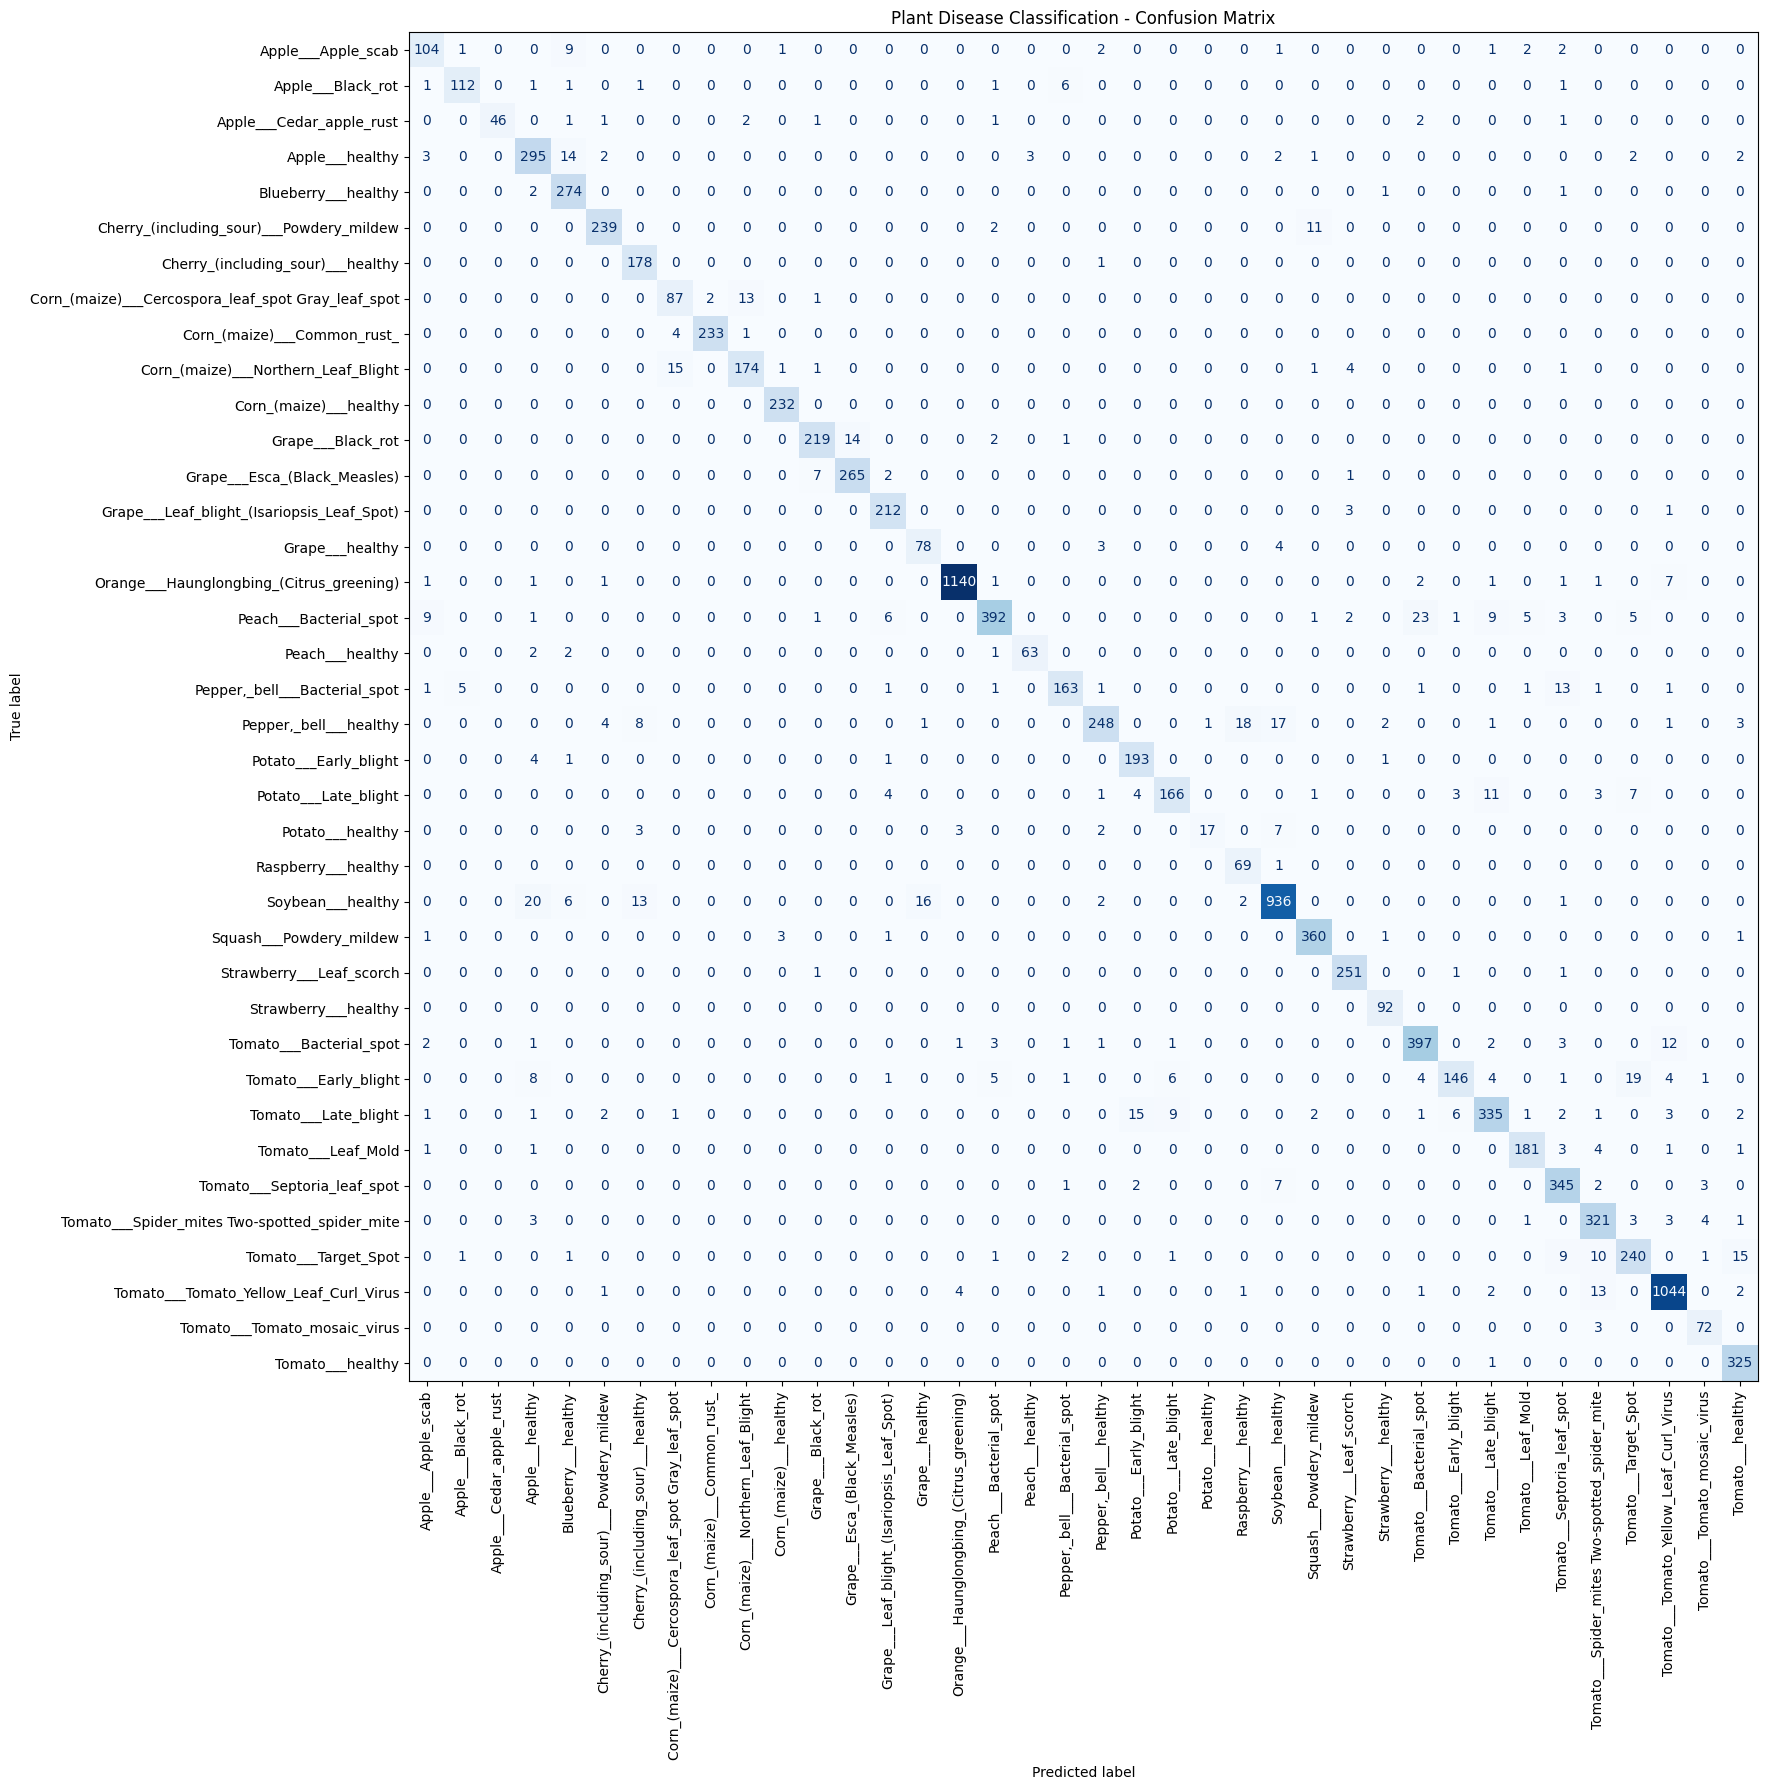

In [ ]:
fig, ax = plt.subplots(figsize=(18, 18))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    display_labels=class_names,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Plant Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_mapping": class_mapping,
        "image_size": image_size
    },
    "plant_disease_cnn.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("plant_disease_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import torch
from PIL import Image

model.eval()

def predict_disease(image):
    if image is None:
        return {"Please upload an image": 1.0}

    image = image.convert("RGB")
    image_tensor = test_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    top_probabilities, top_indices = torch.topk(probabilities, 3)

    results = {
        class_names[idx.item()]: float(prob.item())
        for prob, idx in zip(top_probabilities, top_indices)
    }

    return results


demo = gr.Interface(
    fn=predict_disease,
    inputs=gr.Image(type="pil", label="Upload a Plant Leaf Image"),
    outputs=gr.Label(num_top_classes=3, label="Predicted Disease"),
    title="Plant Disease Classification",
    description="Upload a leaf image to see the model's top predictions."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://62f1e52df1597cbd1a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
